# Расчётные задания по нечеткой логике

Выполнил: студент группы М092602(77)


Зацепин Максим Андреевич

## Задание 1.
Создать функцию ```F(A,a)```, принимающую в качестве аргументов дискретное
нечёткое множество ```A``` и числовой параметр ```0 < a < 1```, и возвращающую ```a```-срез ```A_a``` множества ```A```. Продемонстрировать.

### Решение
Создаем множество A - пары чисел и их принадлежность, отправляем в функцию, на выходе получаем все элементы у которых принадлежность больше или равна порогу

In [149]:
def F(A,a):
    A_a = []
    for x, mu in A.items():
        if mu >= a:
            A_a.append(x)
    return A_a

# def F(A,a):
#     return [x for x, mu in A.items() if mu >= a]


A = {
    1: 0.1, 2: 0.2, 3: 0.3,
    4: 0.4, 5: 0.5, 6: 0.6, 
    7: 0.7, 8: 0.8, 9: 0.9
    }

alpha = 0.5
print(f"Заданное нечёткое множество A: {A}")
print(f"F(A, {alpha}) = {F(A, alpha)}")


Заданное нечёткое множество A: {1: 0.1, 2: 0.2, 3: 0.3, 4: 0.4, 5: 0.5, 6: 0.6, 7: 0.7, 8: 0.8, 9: 0.9}
F(A, 0.5) = [5, 6, 7, 8, 9]


## Задание 2.
Создать функцию ```F(A)```, принимающую в качестве аргумента дискретное нечёткое множество ```A``` и возвращающую ```ближайшее чёткое``` (обычное) множество и эвклидово расстояние от этого ближайшего чёткого множества до ```A```.

### Решение
Возьмем множество из первой задачи. Создадим из него четкое множество и посчитаем Абсолютное евклидово расстояние. расстояние посчитал как сумма разностей принадлежностей в квадрате, и все это под корнем

In [150]:
def F(A):
    A_0 = {}
    sum = 0

    for x, mu in A.items():
        A_0[x] = 1 if mu >= 0.5 else 0
        sum += (mu - A_0[x]) ** 2

    d_e = sum ** 0.5 # sqrt()
    
    return A_0, d_e
    

A = {
    1: 0.1, 2: 0.2, 3: 0.3,
    4: 0.4, 5: 0.5, 6: 0.6, 
    7: 0.7, 8: 0.8, 9: 0.9
    }

nearest_set, distance = F(A)
print(f"Исходное нечёткое множество A: {A}")
print(f"Ближайшее чёткое множество A_0: {nearest_set}")
print(f"Евклидово расстояние d_e(A): {distance:.4f}")

Исходное нечёткое множество A: {1: 0.1, 2: 0.2, 3: 0.3, 4: 0.4, 5: 0.5, 6: 0.6, 7: 0.7, 8: 0.8, 9: 0.9}
Ближайшее чёткое множество A_0: {1: 0, 2: 0, 3: 0, 4: 0, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1}
Евклидово расстояние d_e(A): 0.9220


## Задание 3
Создать функцию `F(A, U)`, принимающую в качестве аргументов:
1. Дискретное универсальное множество `U` и нечёткое дискретное множество `A` с элементами из `U`; 
**или**
2. Некий параметр (`R`), означающий, что универсальное множество `U` — числовая прямая, и функцию принадлежности `m(x)`, задающую нечёткое множество `A`.

Функция возвращает классическое дополнение множества `A`, то есть в первом случае соответствующее дискретное дополнение, а во втором – функцию `1-m(x)`, задающую дополнение непрерывного множества.


Визуализировать, взяв в качестве функции `m(x)`, одну из стандартных функций принадлежности.

### Решение
В дискретном случае для каждого элемента универсального множества считаем степень принадлежности дополнения как `1 - mu`. В непрерывном случае возвращаем новую функцию, которая также вычисляет `1 - m(x)`.

In [151]:
import numpy as np
import matplotlib.pyplot as plt

def F(A, U):
    if U == 'R':
        m = A

        def complement(x):
            return 1 - m(x)

        return complement

    A_complement = {}
    for x in U:
        A_complement[x] = round(1 - A.get(x, 0), 4)

    return A_complement

In [152]:
# Дискретный случай

U = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
A = {
    0: 0.8, 10: 0.6, 20: 0.9,
    30: 0.9, 40: 0.6, 50: 0.9,
    60: 0, 70: 1, 80: 0.2,
    90: 0.3, 100: 0.6
    }

res = F(A, U)

print(f"Универсальное множество U: {U}")
print(f"Нечёткое множество A: {A}")
print(f"Дополнение A: {res}")



Универсальное множество U: [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
Нечёткое множество A: {0: 0.8, 10: 0.6, 20: 0.9, 30: 0.9, 40: 0.6, 50: 0.9, 60: 0, 70: 1, 80: 0.2, 90: 0.3, 100: 0.6}
Дополнение A: {0: 0.2, 10: 0.4, 20: 0.1, 30: 0.1, 40: 0.4, 50: 0.1, 60: 1, 70: 0, 80: 0.8, 90: 0.7, 100: 0.4}


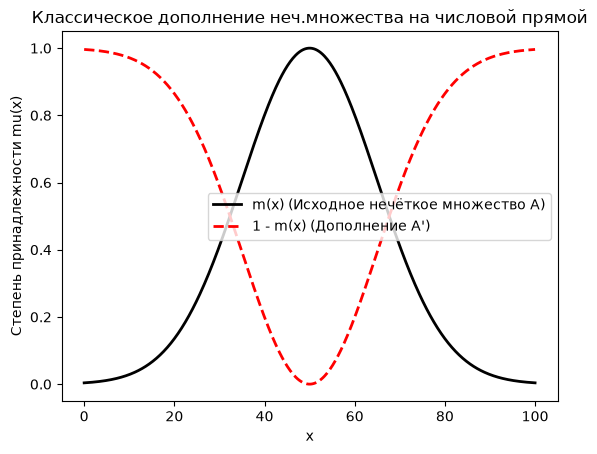

In [153]:
# Непрерывный случай

# Функция принадлежности m(x)
def m(x, c=50, sigma=15):
    return np.exp(-((x - c) ** 2) / (2 * sigma ** 2))

res = F(m, 'R')

# Точки для графика
x_vals = np.linspace(0, 100, 500)
y_orig = m(x_vals)
y_comp = res(x_vals)

plt.figure()
plt.plot(x_vals, y_orig, label='m(x) (Исходное нечёткое множество A)', color='black', linewidth=2)
plt.plot(x_vals, y_comp, label='1 - m(x) (Дополнение A\')', color='red', linestyle='--', linewidth=2)

plt.title('Классическое дополнение неч.множества на числовой прямой')
plt.xlabel('x')
plt.ylabel('Степень принадлежности mu(x)')
plt.legend()
plt.show()

## Задание 4

Аналогично заданию 3 (для дополнения) для дискретного и непрерывного случая создать функции F(A,B), принимающие в качестве аргументов нечёткие множества A и B и возвращающие:
1) объединение `A ∪ B`;
2) пересечение `A ∩ B`;
3) разность `A \ B`;
4) симметрическую разность `𝐴 ∆ B`.

В непрерывном случае визуализировать.

### Решение
В дискретном случае используем словари, где ключами являются элементы множеств, а значениями — степени принадлежности. Для непрерывного случая функция возвращает четыре функции принадлежности.

In [154]:
def F(A, B):
    if callable(A) and callable(B):
        def union(x):
            return max(A(x), B(x))

        def intersection(x):
            return min(A(x), B(x))

        def difference(x):
            return min(A(x), 1 - B(x))

        def sym_difference(x):
            return max(
                min(A(x), 1 - B(x)),
                min(B(x), 1 - A(x))
            )

        return union, intersection, difference, sym_difference

    U = sorted(set(A) | set(B))
    union = {}
    intersection = {}
    difference = {}
    sym_difference = {}

    for x in U:
        mu_a = A.get(x, 0)
        mu_b = B.get(x, 0)

        difference_ab = min(mu_a, 1 - mu_b)
        difference_ba = min(mu_b, 1 - mu_a)

        union[x] = round(max(mu_a, mu_b), 3)
        intersection[x] = round(min(mu_a, mu_b), 3)
        difference[x] = round(difference_ab, 3)
        sym_difference[x] = round(max(difference_ab, difference_ba), 3)

    return union, intersection, difference, sym_difference

# Дискретный случай

A = {0: 0.8, 10: 0.6, 20: 0.9, 30: 0.9, 40: 0.6}
B = {0: 0.1, 10: 0.3, 20: 0.7, 30: 0.7, 40: 0.7}

union, intersection, difference, sym_difference = F(A, B)
print(f"Нечёткое множество A: {A}")
print(f"Нечёткое множество B: {B}")
print(f"A ∪ B: {union}")
print(f"A ∩ B: {intersection}")
print(f"A \\ B: {difference}")
print(f"A ∆ B: {sym_difference}")

Нечёткое множество A: {0: 0.8, 10: 0.6, 20: 0.9, 30: 0.9, 40: 0.6}
Нечёткое множество B: {0: 0.1, 10: 0.3, 20: 0.7, 30: 0.7, 40: 0.7}
A ∪ B: {0: 0.8, 10: 0.6, 20: 0.9, 30: 0.9, 40: 0.7}
A ∩ B: {0: 0.1, 10: 0.3, 20: 0.7, 30: 0.7, 40: 0.6}
A \ B: {0: 0.8, 10: 0.6, 20: 0.3, 30: 0.3, 40: 0.3}
A ∆ B: {0: 0.8, 10: 0.6, 20: 0.3, 30: 0.3, 40: 0.4}


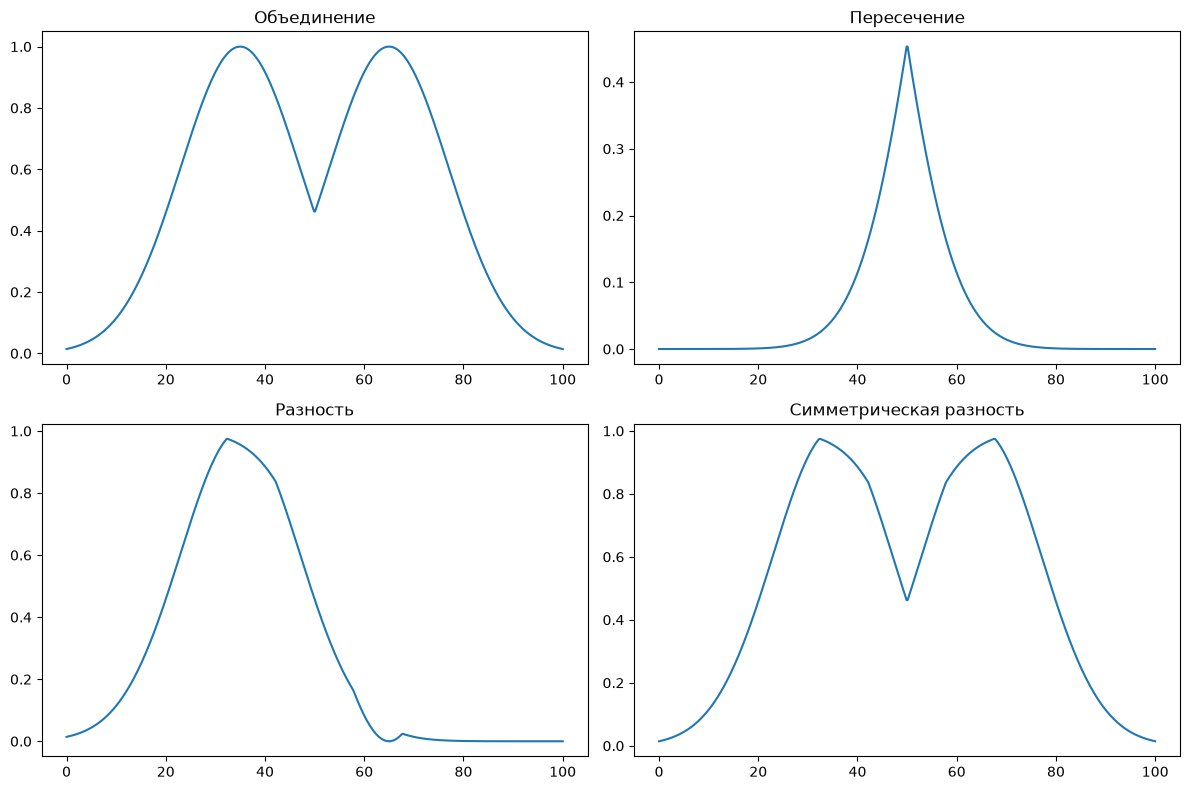

In [155]:
# Непрерывный случай

def func_A(x):
    return np.exp(-((x - 35) ** 2) / (2 * 12 ** 2))


def func_B(x):
    return np.exp(-((x - 65) ** 2) / (2 * 12 ** 2))

union, intersection, difference, sym_difference = F(func_A, func_B)
x_vals = np.linspace(0, 100, 500)

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.plot(x_vals, [union(x) for x in x_vals])
plt.title('Объединение')

plt.subplot(2, 2, 2)
plt.plot(x_vals, [intersection(x) for x in x_vals])
plt.title('Пересечение')

plt.subplot(2, 2, 3)
plt.plot(x_vals, [difference(x) for x in x_vals])
plt.title('Разность')

plt.subplot(2, 2, 4)
plt.plot(x_vals, [sym_difference(x) for x in x_vals])
plt.title('Симметрическая разность')

plt.tight_layout()
plt.show()

## Задание 6

Написать функцию `F(A,B)`, принимающую два НЕЧЁТКИХ бинарных отношения `A(NxM)` и `B(MxK)` и возвращающую их композицию `𝐴°𝐵` `(𝑁𝑥𝐾)`.

### Решение
Для каждого элемента результата берём максимум из минимальных степеней принадлежности соответствующих пар элементов матриц.

In [156]:
def F(A, B):

    sum = {}
    diff = {}
    mul = {}
    div = {}

    for a, mu_a in A.items():
        for b, mu_b in B.items():
            # print(f"({a}, {mu_a}) и ({b}, {mu_b})")
            sum[a + b] = max(min(mu_a, mu_b), sum.get(a + b, 0))
            diff[a - b] = max(min(mu_a, mu_b), diff.get(a - b, 0))
            mul[a * b] = max(min(mu_a, mu_b), mul.get(a *b, 0))
            if b != 0:
                div[round(a / b, 2)] = max(min(mu_a, mu_b), div.get(round(a / b, 2), 0))


    return sum, diff, mul, div

A = {1: 0.1, 2: 0.2, 3: 0.3}
B = {4: 0.4, 5: 0.5, 6: 0.6}

print(f"Нечёткое множество A: {A}")
print(f"Нечёткое множество B: {B}")
print("--------------------------------")
sum, diff, mul, div = F(A, B)
print(f"A + B: {sum}")
print(f"A - B: {diff}")
print(f"A * B: {mul}")
print(f"A / B: {div}")

Нечёткое множество A: {1: 0.1, 2: 0.2, 3: 0.3}
Нечёткое множество B: {4: 0.4, 5: 0.5, 6: 0.6}
--------------------------------
A + B: {5: 0.1, 6: 0.2, 7: 0.3, 8: 0.3, 9: 0.3}
A - B: {-3: 0.3, -4: 0.2, -5: 0.1, -2: 0.3, -1: 0.3}
A * B: {4: 0.1, 5: 0.1, 6: 0.1, 8: 0.2, 10: 0.2, 12: 0.3, 15: 0.3, 18: 0.3}
A / B: {0.25: 0.1, 0.2: 0.1, 0.17: 0.1, 0.5: 0.3, 0.4: 0.2, 0.33: 0.2, 0.75: 0.3, 0.6: 0.3}


## Задание 6

Написать функции `F(A,B`), принимающую два НЕЧЁТКИХ бинарных отношения `A(NxM)` и `B(MxK)` и возвращающую их композицию `𝐴°𝐵` `(𝑁𝑥𝐾)`.

### Решение

In [157]:
def F(A, B):
    N = len(A)
    M = len(A[0])
    K = len(B[0])

    if len(B) != M:
        raise ValueError(f"Размерности не совпадают: столбцов в A ({M}) != строк в B ({len(B)})")

    C = []
    for i in range(N):
        row = []
        for k in range(K):
            values = []
            for j in range(M):
                values.append(min(A[i][j], B[j][k]))
            row.append(max(values))
        C.append(row)

    return C


def output(A):
    for row in A:
        for value in row:
            print(value, end=" ")
        print()


A = [
    [0.2, 0.7, 0.4],
    [0.9, 0.1, 0.5]
    ]

B = [
    [0.6, 0.3],
    [0.8, 0.2],
    [0.1, 0.9]
    ]

res = F(A, B)

print("Матрица A:")
output(A)
print()
print("Матрица B:")
output(B)
print()
print("Композиция A ° B:")
output(res)

Матрица A:
0.2 0.7 0.4 
0.9 0.1 0.5 

Матрица B:
0.6 0.3 
0.8 0.2 
0.1 0.9 

Композиция A ° B:
0.7 0.4 
0.6 0.5 


## Задание 7

Применяя нечеткий вывод Мамдани, построить упрощенную модель экспертной
системы, позволяющей определить количество производимого товара в
зависимости от текущей рыночной конъюнктуры. Входные ЛП: «`Спрос`» (термы
`LD`, `MD`, `HD`), «`Предложение`» (термы `LS`, `MS`, `HS`). На выходе должно
формироваться четкое значение объемов выпуска `Q` (в `%` от максимально
возможного).

Недостающие данные принять самостоятельно.

### Решение
Используем треугольные функции принадлежности для спроса, предложения и объёма выпуска. После применения правил Мамдани объединяем результаты правил и выполняем дефаззификацию методом центра тяжести.

In [158]:
def trimf(x, a, b, c):
    if x <= a or x >= c:
        return 0.0
    if x <= b:
        return (x - a) / (b - a)
    return (c - x) / (c - b)


def mu_low(x):
    if x <= 0:
        return 1.0
    if x < 50:
        return (50 - x) / 50
    return 0.0


def mu_medium(x):
    return trimf(x, 0, 50, 100)


def mu_high(x):
    if x >= 100:
        return 1.0
    if x > 50:
        return (x - 50) / 50
    return 0.0


def mamdani_inference(D, S):
    D_terms = {
        'LD': mu_low(D),
        'MD': mu_medium(D),
        'HD': mu_high(D)
        }
    S_terms = {
        'LS': mu_low(S),
        'MS': mu_medium(S),
        'HS': mu_high(S)
        }

    rules = [
        (min(D_terms['LD'], S_terms['LS']), mu_medium),
        (min(D_terms['LD'], S_terms['MS']), mu_low),
        (min(D_terms['LD'], S_terms['HS']), mu_low),
        (min(D_terms['MD'], S_terms['LS']), mu_high),
        (min(D_terms['MD'], S_terms['MS']), mu_medium),
        (min(D_terms['MD'], S_terms['HS']), mu_low),
        (min(D_terms['HD'], S_terms['LS']), mu_high),
        (min(D_terms['HD'], S_terms['MS']), mu_high),
        (min(D_terms['HD'], S_terms['HS']), mu_medium)
        ]

    numerator = 0
    denominator = 0

    for q in range(101):
        mu_result = 0
        for weight, term in rules:
            mu_rule = min(weight, term(q))
            mu_result = max(mu_result, mu_rule)

        numerator += q * mu_result
        denominator += mu_result

    if denominator == 0:
        return 50

    return numerator / denominator


test = [
    (70, 30),
    (10, 90),
    (60, 40),
    (90, 90)
    ]

for D, S in test:
    Q = mamdani_inference(D, S)
    print(f"Спрос: {D}, предложение: {S} -> объём выпуска: {Q:.2f}%")

Спрос: 70, предложение: 30 -> объём выпуска: 53.97%
Спрос: 10, предложение: 90 -> объём выпуска: 32.36%
Спрос: 60, предложение: 40 -> объём выпуска: 51.05%
Спрос: 90, предложение: 90 -> объём выпуска: 50.00%
